
# 1, House Price Prediction – King County

## Affärsproblem
En mäklarfirma vill kunna förutsäga bostadspriser i King County, USA, baserat på tidigare försäljningar.

## Syfte
Vi ska undersöka om Machine Learning kan användas för att uppskatta bostadspriser med hjälp av information som boyta, antal rum, byggår 
och geografiskt läge.

Vi kommer att utforska datasetet, förbereda datan, träna olika regressionsmodeller och jämföra hur väl de förutsäger bostadspriser.


## 1. Importera bibliotek

Vi importerar de Python-bibliotek som behövs för att hantera data, utföra beräkningar och skapa visualiseringar:
  

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Allt fungerar!")

Allt fungerar!


In [3]:

## 2. Läsa in datasetet

df = pd.read_csv("kc_house_data.csv")

df.head()



,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


 
## 3. Utforskande dataanalys (EDA)

Vi undersöker datasetets storlek, kolumner och datatyper för att få en bättre förståelse av informationen innan vi bygger vår ML-modell.


In [4]:

print("Antal rader och kolumner:", df.shape)

df.info()

Antal rader och kolumner: (21613, 21)
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 no

In [5]:

# Kontrollera saknade värden
print("Saknade värden:")
print(df.isnull().sum())

# Kontrollera helt identiska rader
print("\nAntal dubblettrader:", df.duplicated().sum())

# Visa statistisk sammanfattning
df.describe()

Saknade värden:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

Antal dubblettrader: 0


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [6]:

# Undersök bostäder med ovanligt många sovrum
df[df["bedrooms"] > 10][["price", "bedrooms", "bathrooms", "sqft_living"]]

,price,bedrooms,bathrooms,sqft_living
8757,520000.0,11,3.00,3000
15870,640000.0,33,1.75,1620


In [7]:

# Undersök bostäder med 0 sovrum eller 0 badrum
df[(df["bedrooms"] == 0) | (df["bathrooms"] == 0)][
    ["price", "bedrooms", "bathrooms", "sqft_living"]
]


,price,bedrooms,bathrooms,sqft_living
875,1095000.0,0,0.00,3064
1149,75000.0,1,0.00,670
3119,380000.0,0,0.00,1470
3467,288000.0,0,1.50,1430
4868,228000.0,0,1.00,390
5832,280000.0,1,0.00,600
6994,1295650.0,0,0.00,4810
8477,339950.0,0,2.50,2290
8484,240000.0,0,2.50,1810
9773,355000.0,0,0.00,2460



### Sammanfattning av datakvalitet

Datasetet innehåller 21 613 bostadsförsäljningar och 21 kolumner.

- Inga saknade värden.
- Inga helt identiska rader.
- Några misstänkta observationer, bland annat en bostad med 33 sovrum och flera bostäder med 0 sovrum eller 0 badrum.

Vi behåller originaldatan tills vidare och undersöker senare hur avvikande värden kan påverka modellens resultat.


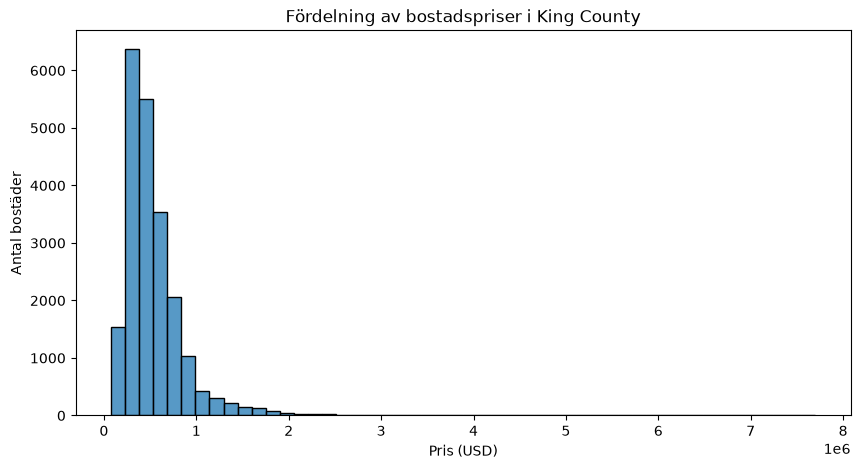

In [8]:

plt.figure(figsize=(10, 5))

sns.histplot(df["price"], bins=50)

plt.title("Fördelning av bostadspriser i King County")
plt.xlabel("Pris (USD)")
plt.ylabel("Antal bostäder")

plt.show()



### Observation – Bostadspriser

Prisfördelningen är högerskev. De flesta bostäder säljs för under cirka 1 miljon USD, medan ett mindre antal bostäder har betydligt högre priser.

Detta är viktigt att ta hänsyn till när vi senare utvärderar vår ML-modell.


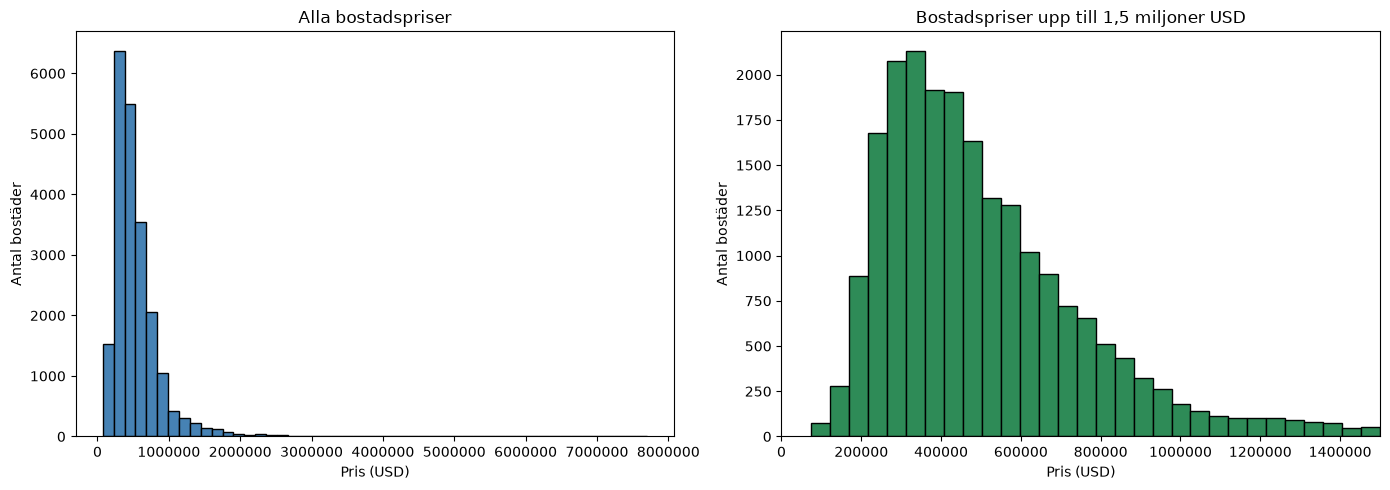

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Diagram 1 – Alla bostadspriser
axes[0].hist(
    df["price"],
    bins=50,
    color="steelblue",
    edgecolor="black"
)

axes[0].set_title("Alla bostadspriser")
axes[0].set_xlabel("Pris (USD)")
axes[0].set_ylabel("Antal bostäder")
axes[0].ticklabel_format(style="plain", axis="x")

# Diagram 2 – Fokus på priser upp till 1,5 miljoner USD
axes[1].hist(
    df.loc[df["price"] <= 1_500_000, "price"],
    bins=30,
    color="seagreen",
    edgecolor="black"
)

axes[1].set_xlim(0, 1_500_000)
axes[1].set_title("Bostadspriser upp till 1,5 miljoner USD")
axes[1].set_xlabel("Pris (USD)")
axes[1].set_ylabel("Antal bostäder")
axes[1].ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

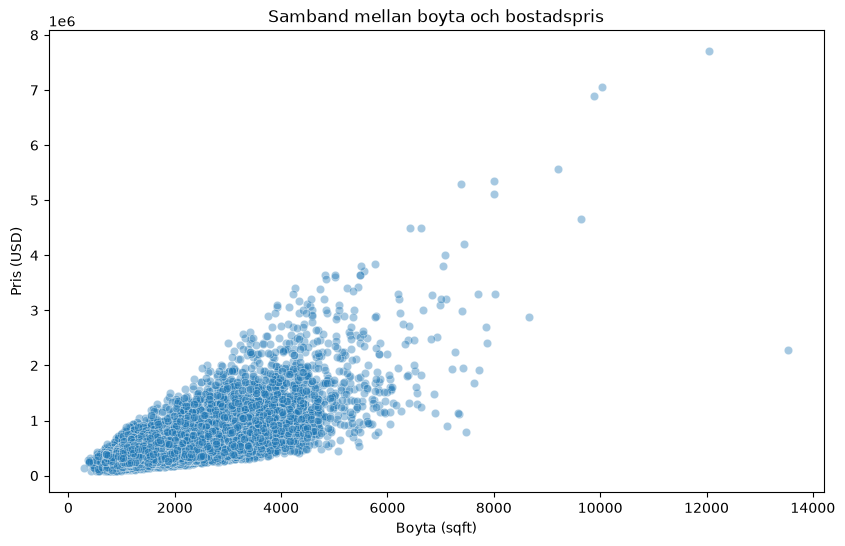

In [9]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="sqft_living",
    y="price",
    alpha=0.4
)

plt.title("Samband mellan boyta och bostadspris")
plt.xlabel("Boyta (sqft)")
plt.ylabel("Pris (USD)")

plt.show()



### Observation – Boyta och pris

Diagrammet visar ett positivt samband mellan boyta och försäljningspris. Större bostäder tenderar att vara dyrare.

Det finns samtidigt stor variation i priserna, vilket tyder på att även andra faktorer påverkar bostadens värde.


In [10]:

# Beräkna korrelation med bostadspris
correlation = df.corr(numeric_only=True)["price"].sort_values(ascending=False)

print(correlation)


price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
sqft_basement    0.323816
bedrooms         0.308350
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
id              -0.016762
zipcode         -0.053203
Name: price, dtype: float64


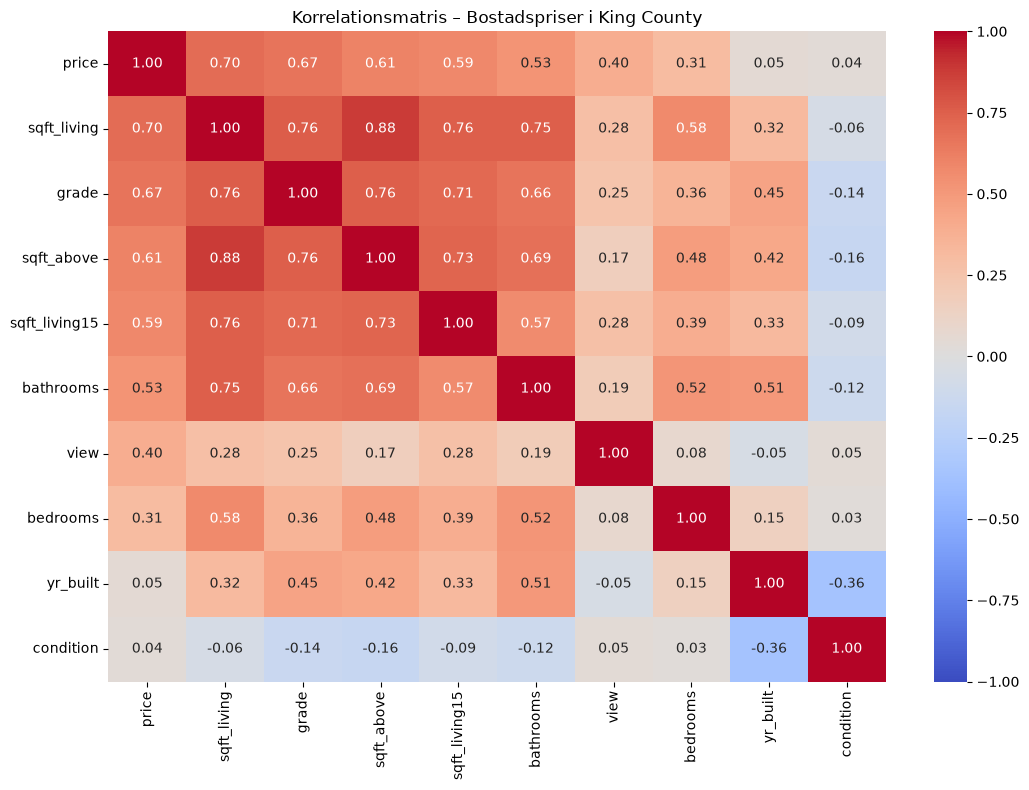

In [41]:
# Välj variabler för korrelationsmatrisen
columns = [
    "price",
    "sqft_living",
    "grade",
    "sqft_above",
    "sqft_living15",
    "bathrooms",
    "bedrooms",
    "view",
    "condition",
    "yr_built"
]

# Beräkna korrelationerna
corr_matrix = df[columns].corr()

# Sortera variablerna efter korrelation med pris
sorted_columns = corr_matrix["price"].sort_values(
    ascending=False
).index

corr_matrix = corr_matrix.loc[sorted_columns, sorted_columns]

# Skapa heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Korrelationsmatris – Bostadspriser i King County")
plt.tight_layout()
plt.show()


### Observation – Korrelationer

Boyta (`sqft_living`) har starkast positiv korrelation med bostadspriset (0,70), följt av byggkvalitet (`grade`, 0,67).

Antalet sovrum har ett svagare samband med priset än boytan.

Resultatet hjälper oss att identifiera möjliga variabler för ML-modellen, men korrelation ensam avgör inte vilka variabler som är bäst.


## 4. Förbereda data för Machine Learning

Vi väljer sex bostadsegenskaper som modellen ska använda för att förutsäga försäljningspriset. 
Vi börjar med en enkel modell och kommer senare att undersöka om fler variabler förbättrar resultatet.
    

In [11]:
features = ["sqft_living", "grade", "bathrooms",
            "view", "bedrooms", "lat"]

X = df[features]
y = df["price"]

print("Antal variabler:", X.shape[1])
print("Antal bostäder:", X.shape[0])

Antal variabler: 6
Antal bostäder: 21613



### Uppdelning i tränings- och testdata

Vi delar upp datasetet i 80 % träningsdata och 20 % testdata. Modellen tränas på träningsdatan och utvärderas sedan på bostäder
den inte tidigare har sett.


In [12]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Träningsdata:", X_train.shape)
print("Testdata:", X_test.shape)


Träningsdata: (17290, 6)
Testdata: (4323, 6)



## 5. Träna ML-modellen – Linear Regression

Vi använder linjär regression för att förutsäga bostadspriser baserat på sex utvalda bostadsegenskaper.

Modellen tränas på 80 % av datasetet. Därefter använder vi resterande 20 % för att utvärdera hur väl modellen kan förutsäga priser på nya bostäder.


In [13]:

from sklearn.linear_model import LinearRegression

# Skapa modellen
model = LinearRegression()

# Träna modellen med träningsdata
model.fit(X_train, y_train)

print("Modellen har tränats!")


Modellen har tränats!



## 6. Förutsäga bostadspriser

Vi använder vår tränade modell för att förutsäga priser på testdatan. Sedan jämför vi modellens uppskattningar med de verkliga försäljningspriserna.


In [14]:
# Förutsäg priser
y_pred = model.predict(X_test)

# Visa bostadsegenskaper tillsammans med verkliga och förutsagda priser
resultat = X_test.copy()

resultat["Verkligt pris"] = y_test
resultat["Förutsagt pris"] = y_pred

resultat.head(10).style.format({
    "Verkligt pris": "{:,.0f} USD",
    "Förutsagt pris": "{:,.0f} USD",
}, thousands=" ")


,sqft_living,grade,bathrooms,view,bedrooms,lat,Verkligt pris,Förutsagt pris
735,2 070,8,2.250000,0,4,47.438800,365 000 USD,442 208 USD
2830,2 900,8,3.000000,0,5,47.678400,865 000 USD,734 489 USD
4106,3 770,11,2.500000,2,4,47.564600,1 038 000 USD,1 277 714 USD
16218,4 560,12,3.500000,2,3,47.699500,1 490 000 USD,1 615 632 USD
19964,2 550,9,2.500000,0,3,47.664700,711 000 USD,785 488 USD
1227,1 710,7,2.000000,0,4,47.394700,211 000 USD,269 181 USD
18849,2 690,9,2.500000,0,4,47.659600,790 000 USD,784 481 USD
19369,1 800,7,2.500000,0,3,47.659900,680 000 USD,483 746 USD
20164,1 600,8,2.500000,0,3,47.534400,384 500 USD,434 433 USD
7139,910,7,1.000000,0,2,47.634100,605 000 USD,328 365 USD



## 7. Utvärdera modellen

Vi utvärderar vår linjära regressionsmodell med MAE, RMSE och R² för att undersöka hur väl modellen förutsäger bostadspriser på testdatan.


In [15]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:,.0f} USD")
print(f"RMSE: {rmse:,.0f} USD")
print(f"R²: {r2:.3f}")


MAE: 139,685 USD
RMSE: 233,196 USD
R²: 0.640



### Resultat – Linear Regression

Vår första modell gav följande resultat på testdatan:

- MAE: 139 685 USD
- RMSE: 233 196 USD
- R²: 0,640

Modellen förklarar cirka 64 % av variationen i bostadspriserna, men gör fortfarande relativt stora prisfel.

Vi kommer därför att undersöka om andra algoritmer eller fler bostadsegenskaper kan förbättra förutsägelserna.



## 8. Undersöka extremvärden (Outliers)

Vi undersöker bostäder med ovanliga värden, exempelvis mycket höga priser, stora boytor eller extremt många sovrum.

Syftet är att identifiera möjliga felregistreringar och undersöka om extremvärden kan påverka modellens resultat. Vi behåller originaldatan tills vidare.


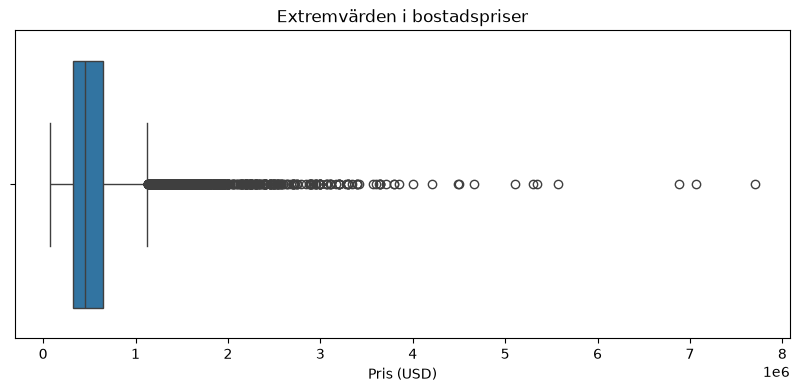

In [16]:

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["price"])

plt.title("Extremvärden i bostadspriser")
plt.xlabel("Pris (USD)")

plt.show()

### Undersökning av misstänkta bostäder

Vi undersöker två typer av avvikande observationer:

- De 10 dyraste bostäderna för att förstå om de höga priserna verkar rimliga.
- Bostäder med 0 sovrum, 0 badrum eller fler än 20 sovrum, eftersom dessa värden kan tyda på felregistreringar.

Vi jämför bostädernas egenskaper innan vi beslutar om eventuell datarensning.

In [17]:

# Visa de 10 dyraste bostäderna
print("De 10 dyraste bostäderna:")

display(df.nlargest(10, "price")[
    ["price", "sqft_living", "bedrooms", "bathrooms",
     "grade", "waterfront", "view"]
])

# Visa bostäder med misstänkta antal sovrum eller badrum
print("Bostäder med misstänkta värden:")

suspect = df[
    (df["bedrooms"] == 0) |
    (df["bathrooms"] == 0) |
    (df["bedrooms"] > 20)
]

display(suspect[
    ["price", "sqft_living", "bedrooms", "bathrooms",
     "grade", "waterfront", "view"]
])


De 10 dyraste bostäderna:


,price,sqft_living,bedrooms,bathrooms,grade,waterfront,view
7252,7700000.0,12050,6,8.00,13,0,3
3914,7062500.0,10040,5,4.50,11,1,2
9254,6885000.0,9890,6,7.75,13,0,4
4411,5570000.0,9200,5,5.75,13,0,0
1448,5350000.0,8000,5,5.00,12,0,4
1315,5300000.0,7390,6,6.00,12,1,4
1164,5110800.0,8010,5,5.25,12,1,4
8092,4668000.0,9640,5,6.75,12,1,4
2626,4500000.0,6640,5,5.50,12,1,4
8638,4489000.0,6430,4,3.00,12,0,0


Bostäder med misstänkta värden:


,price,sqft_living,bedrooms,bathrooms,grade,waterfront,view
875,1095000.0,3064,0,0.00,7,0,2
1149,75000.0,670,1,0.00,3,0,0
3119,380000.0,1470,0,0.00,8,0,2
3467,288000.0,1430,0,1.50,7,0,0
4868,228000.0,390,0,1.00,4,0,0
5832,280000.0,600,1,0.00,3,0,0
6994,1295650.0,4810,0,0.00,12,0,0
8477,339950.0,2290,0,2.50,8,0,0
8484,240000.0,1810,0,2.50,7,0,0
9773,355000.0,2460,0,0.00,8,0,0


In [18]:

# Välj bostäder utan misstänkta värden
mask = (
    (X_train["bedrooms"] > 0) &
    (X_train["bedrooms"] <= 20) &
    (X_train["bathrooms"] > 0)
)

# Skapa rensad träningsdata
X_train_clean = X_train[mask]
y_train_clean = y_train[mask]

print("Före rensning:", len(X_train))
print("Efter rensning:", len(X_train_clean))
print("Borttagna bostäder:", len(X_train) - len(X_train_clean))


Före rensning: 17290
Efter rensning: 17278
Borttagna bostäder: 12


In [19]:

# Skapa och träna modellen med rensad träningsdata
model_clean = LinearRegression()
model_clean.fit(X_train_clean, y_train_clean)

# Förutsäg priser på samma testdata som tidigare
y_pred_clean = model_clean.predict(X_test)

# Utvärdera den rensade modellen
mae_clean = mean_absolute_error(y_test, y_pred_clean)
rmse_clean = np.sqrt(mean_squared_error(y_test, y_pred_clean))
r2_clean = r2_score(y_test, y_pred_clean)

# Jämför båda modellerna
comparison = pd.DataFrame({
    "Modell": ["Original", "Rensad"],
    "MAE": [mae, mae_clean],
    "RMSE": [rmse, rmse_clean],
    "R²": [r2, r2_clean]
})

comparison.style.format({
    "MAE": "{:,.0f} USD",
    "RMSE": "{:,.0f} USD",
    "R²": "{:.3f}"
}, thousands=" ")


,Modell,MAE,RMSE,R²
0,Original,139 685 USD,233 196 USD,0.640
1,Rensad,139 716 USD,233 103 USD,0.641



### Resultat – Hantering av extremvärden

Vi identifierade 17 misstänkta observationer i datasetet, varav 12 fanns i träningsdatan.

Vi tränade om Linear Regression efter att ha exkluderat dessa 12 observationer och jämförde resultatet med originalmodellen.

Resultatet visade endast marginella skillnader i MAE, RMSE och R². Vi kunde därför inte se någon tydlig förbättring av rensningen.

Vi behåller originalmodellen som utgångspunkt för kommande experiment.



## 9. Utökad Linear Regression

Vi undersöker om fler bostadsegenskaper kan förbättra modellens förutsägelser.

Vi utökar från 6 till 13 variabler och tränar en ny version av Linear Regression.

Syftet är att jämföra modellen med vår ursprungliga modell och undersöka om mer information ger bättre resultat.


In [20]:

# Utökad lista med bostadsegenskaper
features_extended = [
    "sqft_living",
    "grade",
    "bathrooms",
    "view",
    "bedrooms",
    "lat",
    "long",
    "waterfront",
    "sqft_living15",
    "sqft_lot",
    "condition",
    "yr_built",
    "sqft_basement"
]

# Skapa en ny uppsättning features
X_extended = df[features_extended]

print("Antal variabler:", X_extended.shape[1])
print("Antal bostäder:", X_extended.shape[0])


Antal variabler: 13
Antal bostäder: 21613


In [21]:

# Använd samma bostäder som i den ursprungliga modellen
X_train_extended = X_extended.loc[X_train.index]
X_test_extended = X_extended.loc[X_test.index]

print("Träningsdata:", X_train_extended.shape)
print("Testdata:", X_test_extended.shape)


Träningsdata: (17290, 13)
Testdata: (4323, 13)


In [22]:

from sklearn.model_selection import cross_val_score

# Skapa modellen med 13 variabler
model_extended = LinearRegression()

# Korsvalidera modellen med 6 variabler
cv_original = cross_val_score(
    LinearRegression(), X_train, y_train,
    cv=5, scoring="neg_mean_absolute_error"
)

# Korsvalidera modellen med 13 variabler
cv_extended = cross_val_score(
    model_extended, X_train_extended, y_train,
    cv=5, scoring="neg_mean_absolute_error"
)

# Jämför genomsnittligt MAE
print(f"6 variabler - MAE: {-cv_original.mean():,.0f} USD")
print(f"13 variabler - MAE: {-cv_extended.mean():,.0f} USD")


6 variabler - MAE: 135,674 USD
13 variabler - MAE: 125,800 USD



### Resultat – Utökad Linear Regression

Vi jämförde Linear Regression med 6 respektive 13 variabler genom 5-fold cross-validation.

- 6 variabler: MAE 135 674 USD
- 13 variabler: MAE 125 800 USD

Den utökade modellen minskade det genomsnittliga prisfelet med cirka 7,3 %.

Resultatet visar att ytterligare bostadsegenskaper kan förbättra modellens förutsägelser.



## 10. Decision Tree Regressor

Vi testar Decision Tree Regressor för att undersöka om en annan ML-algoritm kan förutsäga bostadspriser bättre än Linear Regression.

Beslutsträd delar upp datan utifrån bostädernas egenskaper och kan fånga mer komplexa samband.

Vi använder samma 13 variabler och jämför modellerna genom 5-fold cross-validation.


In [23]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score

# Skapa beslutsträdsmodellen
tree_model = DecisionTreeRegressor(
    max_depth=8,
    random_state=42
)

# Utvärdera med 5-fold cross-validation
cv_tree = cross_val_score(
    tree_model,
    X_train_extended,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

# Jämför med Linear Regression (13 variabler)
print(f"Linear Regression - MAE: {-cv_extended.mean():,.0f} USD")
print(f"Decision Tree - MAE: {-cv_tree.mean():,.0f} USD")

Linear Regression - MAE: 125,800 USD
Decision Tree - MAE: 95,177 USD



### Resultat – Decision Tree

Vi jämförde Decision Tree Regressor med vår utökade Linear Regression genom 5-fold cross-validation.

- Linear Regression: MAE 125 800 USD
- Decision Tree: MAE 95 177 USD

Decision Tree minskade det genomsnittliga prisfelet med cirka 24,3 %.

Resultatet tyder på att beslutsträdet bättre fångar sambanden mellan bostadsegenskaper och försäljningspriser.



## 11. Random Forest Regressor

Vi testar Random Forest för att undersöka om flera kombinerade beslutsträd kan ge bättre prisprognoser än ett enskilt Decision Tree.

Vi använder samma 13 variabler och 5-fold cross-validation för att jämföra algoritmerna.


In [24]:

from sklearn.ensemble import RandomForestRegressor

# Skapa Random Forest med 100 beslutsträd
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

# Utvärdera med 5-fold cross-validation
cv_rf = cross_val_score(
    rf_model,
    X_train_extended,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

# Jämför våra tre algoritmer
print(f"Linear Regression - MAE: {-cv_extended.mean():,.0f} USD")
print(f"Decision Tree - MAE: {-cv_tree.mean():,.0f} USD")
print(f"Random Forest - MAE: {-cv_rf.mean():,.0f} USD")


Linear Regression - MAE: 125,800 USD
Decision Tree - MAE: 95,177 USD
Random Forest - MAE: 71,949 USD



### Resultat – Jämförelse av tre ML-algoritmer

Vi jämförde Linear Regression, Decision Tree och Random Forest genom 5-fold cross-validation med samma 13 bostadsegenskaper.

- Linear Regression: MAE 125 800 USD
- Decision Tree: MAE 95 177 USD
- Random Forest: MAE 71 949 USD

Random Forest gav lägst genomsnittligt prisfel och förbättrade resultatet med cirka 42,8 % jämfört med Linear Regression.

Vi väljer därför Random Forest som den mest lovande modellen för vidare utvärdering.



## 12. Slutlig utvärdering av Random Forest

Random Forest gav bäst resultat under korsvalideringen och valdes därför för slutlig utvärdering.

Vi tränar modellen på hela träningsdatan och testar den sedan på de 4 323 bostäder som inte använts under träning eller modellval.

Vi mäter resultatet med MAE, RMSE och R².




In [25]:

# Träna Random Forest på hela träningsdatan
rf_model.fit(X_train_extended, y_train)

# Förutsäg priser på testdatan
y_pred_rf = rf_model.predict(X_test_extended)

# Beräkna utvärderingsmått
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"MAE: {mae_rf:,.0f} USD")
print(f"RMSE: {rmse_rf:,.0f} USD")
print(f"R²: {r2_rf:.3f}")


MAE: 76,101 USD
RMSE: 151,340 USD
R²: 0.848



## 13. Analys av modellens fel

Vi undersöker hur Random Forest presterar för bostäder i olika prisklasser.

Syftet är att identifiera var modellen gör stora fel och avgöra vilka förbättringar som kan vara mest relevanta.


In [26]:

# Skapa en tabell med verkliga och förutsagda priser
error_analysis = pd.DataFrame({
    "Verkligt pris": y_test,
    "Förutsagt pris": y_pred_rf
})

# Beräkna absoluta fel och procentuella fel
error_analysis["Absolut fel"] = abs(
    error_analysis["Verkligt pris"] -
    error_analysis["Förutsagt pris"]
)

error_analysis["Procentuellt fel"] = (
    error_analysis["Absolut fel"] /
    error_analysis["Verkligt pris"] * 100
)

# Dela in bostäderna efter verkligt pris
error_analysis["Prisklass"] = pd.cut(
    error_analysis["Verkligt pris"],
    bins=[0, 300000, 600000, 1000000, float("inf")],
    labels=["Under 300k", "300k–600k", "600k–1M", "Över 1M"]
)

# Sammanfatta resultat per prisklass
summary = error_analysis.groupby(
    "Prisklass", observed=True
).agg(
    Antal=("Absolut fel", "count"),
    MAE=("Absolut fel", "mean"),
    Medelfel_procent=("Procentuellt fel", "mean")
)

summary.round(1)


,Antal,MAE,Medelfel_procent
Prisklass,,,
Under 300k,918,41842.6,19.1
300k–600k,2108,50976.2,11.7
600k–1M,977,92720.5,12.2
Över 1M,320,289149.5,17.8



### Resultat – Felanalys per prisklass

Random Forest presterar bäst för bostäder mellan 300 000 och 1 miljon USD, där det genomsnittliga procentuella felet ligger omkring 12 %.

För bostäder under 300 000 USD är felet 19,1 %, medan bostäder över 1 miljon USD har ett fel på 17,8 %.

Resultatet visar att modellen har svårare att förutsäga priser i de lägsta och högsta prisklasserna.


### 13. Hyperparameteroptimering – Random Forest

Vi undersöker om Random Forest kan förbättras genom att testa olika inställningar för antal träd, maxdjup och minsta antal observationer per blad.

Vi använder RandomizedSearchCV med 5-fold cross-validation på träningsdatan och jämför resultaten med vårt tidigare CV-MAE på 71 949 USD.

Testdatan används inte vid optimeringen.

In [27]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, 16, 20, None],
    "min_samples_leaf": [1, 2, 4]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=12,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train_extended, y_train)

print("Bästa inställningar:", rf_search.best_params_)
print("Bästa CV-MAE:", round(-rf_search.best_score_, 0), "USD")

Bästa inställningar: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_depth': None}
Bästa CV-MAE: 69412.0 USD


**Resultat – Hyperparameteroptimering**

Bästa inställningar:
- `n_estimators = 200`
- `max_depth = None`
- `min_samples_leaf = 2`

CV-MAE förbättrades från 71 949 USD till 69 412 USD, en minskning med cirka 3,5 %.

Optimeringen gav alltså ett något lägre genomsnittligt fel vid korsvalidering. Nästa steg är att utvärdera den optimerade modellen på testdatan.

In [29]:
# Utvärdera den optimerade Random Forest
best_rf = rf_search.best_estimator_

y_pred_best_rf = best_rf.predict(X_test_extended)

mae_best_rf = mean_absolute_error(y_test, y_pred_best_rf)
rmse_best_rf = np.sqrt(mean_squared_error(y_test, y_pred_best_rf))
r2_best_rf = r2_score(y_test, y_pred_best_rf)

print(f"MAE: {mae_best_rf:,.0f} USD")
print(f"RMSE: {rmse_best_rf:,.0f} USD")
print(f"R²: {r2_best_rf:.3f}")

MAE: 73,050 USD
RMSE: 147,857 USD
R²: 0.855


**Resultat – Optimerad Random Forest**

Den optimerade modellen gav följande resultat på testdatan:

- MAE: 73 050 USD (tidigare 76 101 USD)
- RMSE: 147 857 USD (tidigare 151 340 USD)
- R²: 0,855 (tidigare 0,848)

Hyperparameteroptimeringen minskade MAE med cirka 4 %. Förbättringen är begränsad men syns i samtliga utvärderingsmått.

Eftersom testdatan har använts tidigare betraktas detta som en kompletterande utvärdering, inte ett nytt oberoende sluttest.

In [38]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(y_test, y_pred_best_rf) * 100

print(f"Genomsnittligt procentuellt prisfel (MAPE): {mape:.1f}%")


Genomsnittligt procentuellt prisfel (MAPE): 13.2%


**Resultat – Procentuellt prisfel**

Den optimerade Random Forest fick ett MAPE på 13,2 %, vilket innebär att modellens förutsägelser i genomsnitt avviker med 13,2 % från de verkliga bostadspriserna.

Det ger ett kompletterande mått på modellens prestation utöver MAE, RMSE och R².

### 14. Visualisering – Feature Importance

Vi undersöker vilka variabler den optimerade Random Forest-modellen använder mest i sina prisprognoser.

Feature importance visar hur viktiga variablerna är för modellens prediktioner, men ska inte tolkas som bevis på orsakssamband.

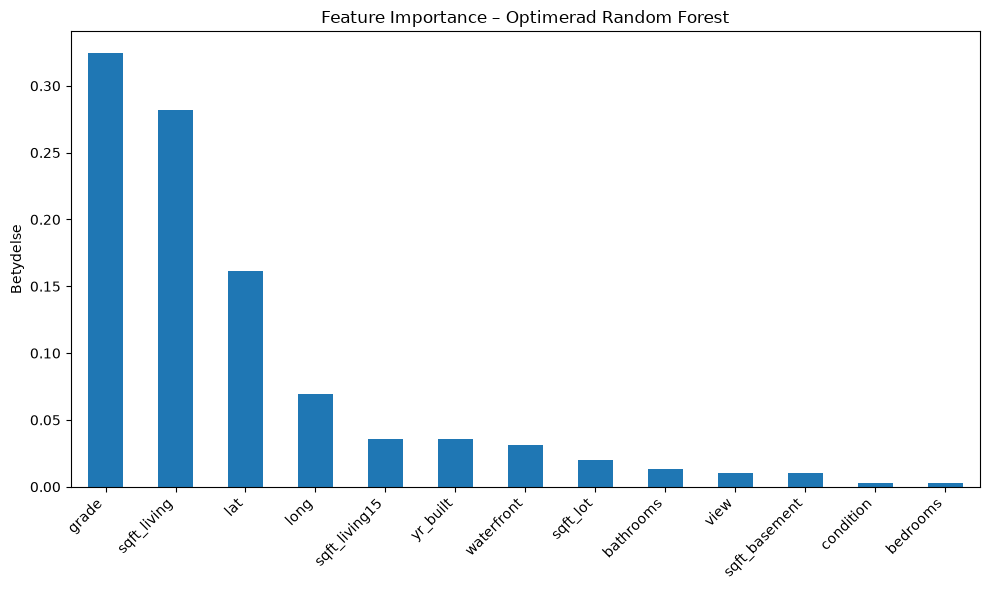

In [39]:
# Feature importance för optimerad Random Forest
feature_importance = pd.Series(
    best_rf.feature_importances_,
    index=X_train_extended.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
feature_importance.plot(kind="bar")

plt.title("Feature Importance – Optimerad Random Forest")
plt.ylabel("Betydelse")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

**Resultat – Feature Importance**

Byggkvalitet (`grade`), boyta (`sqft_living`) och geografiskt läge (`lat`, `long`) har störst betydelse i vår Random Forest-modell.

Antal sovrum och bostadens skick har däremot låg feature importance.

Resultatet visar vilka variabler modellen använder mest, men säger inte nödvändigtvis vilka faktorer som orsakar högre bostadspriser.

### 15. Visualisering – Verkligt pris vs förutsagt pris

Vi jämför de verkliga bostadspriserna med priserna som vår optimerade Random Forest har förutsagt.

Syftet är att visualisera modellens träffsäkerhet och undersöka hur stora skillnaderna är mellan verkliga och förutsagda priser.

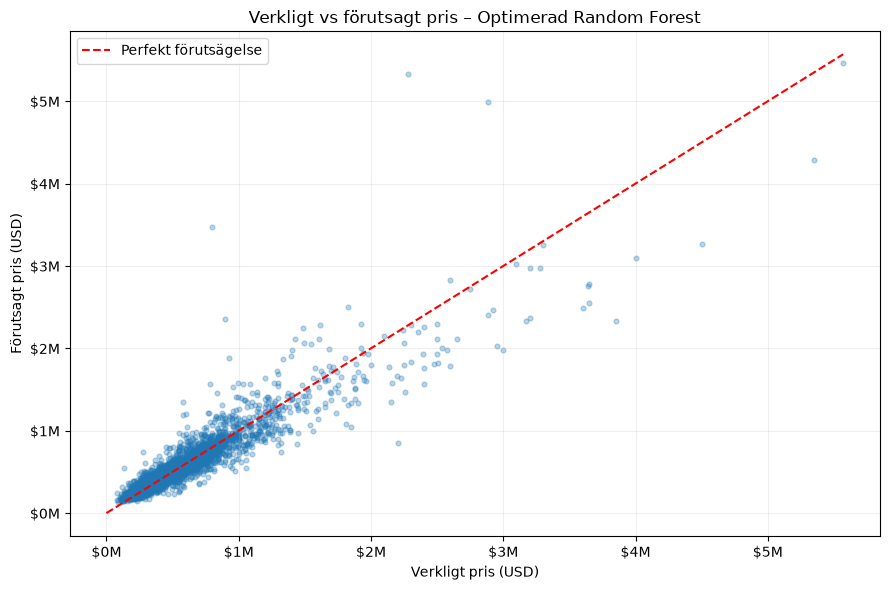

In [37]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred_best_rf, alpha=0.3, s=12)

# Referenslinje för perfekta förutsägelser
max_price = max(y_test.max(), y_pred_best_rf.max())

plt.plot(
    [0, max_price],
    [0, max_price],
    "r--",
    label="Perfekt förutsägelse"
)

plt.xlabel("Verkligt pris (USD)")
plt.ylabel("Förutsagt pris (USD)")
plt.title("Verkligt vs förutsagt pris – Optimerad Random Forest")
plt.legend()
plt.grid(alpha=0.2)
from matplotlib.ticker import FuncFormatter

# Visa axlarna i miljoner USD
millions = FuncFormatter(lambda x, pos: f"${x/1_000_000:g}M")

plt.gca().xaxis.set_major_formatter(millions)
plt.gca().yaxis.set_major_formatter(millions)
plt.tight_layout()
plt.show()

**Resultat – Verkliga och förutsagda priser**

- På den röda linjen: Modellen förutsåg exakt rätt pris.

- Ovanför linjen: Modellen överskattade priset.

- Under linjen: Modellen underskattade priset.

  
Modellens förutsägelser ligger generellt nära de verkliga priserna, särskilt i lägre och medelhöga prisklasser.

För dyrare bostäder ser vi större avvikelser, ofta i form av underskattade priser.

Det visar att modellen fångar viktiga samband men fortfarande har begränsningar, särskilt vid värdering av dyra bostäder.


### 16. Visualisering – Jämförelse mellan ML-modeller

Vi jämför modellernas genomsnittliga absoluta prisfel (CV-MAE) från 5-fold cross-validation.

Ett lägre MAE innebär bättre träffsäkerhet. Syftet är att visualisera vilken modell som presterade bäst.

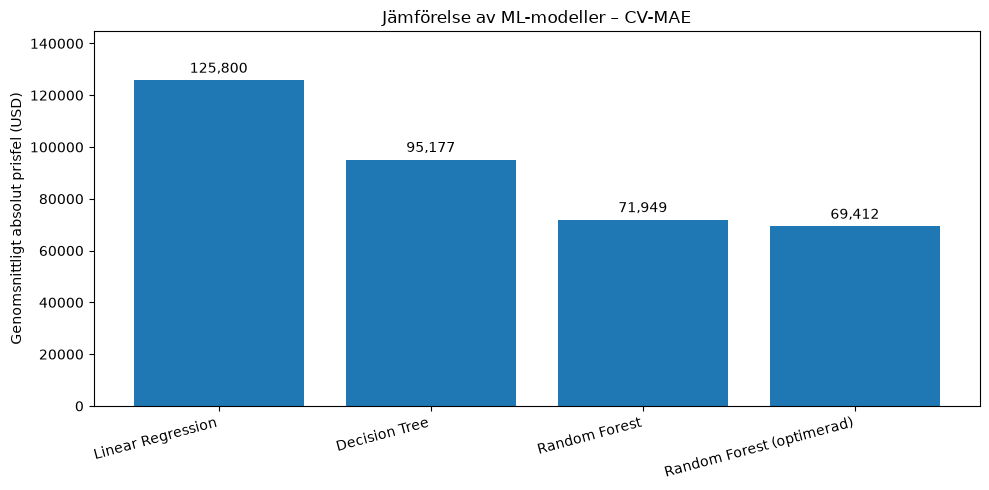

In [32]:
# Jämför modellernas CV-MAE
models = [
    "Linear Regression",
    "Decision Tree",
    "Random Forest",
    "Random Forest (optimerad)"
]

mae_values = [
    -cv_extended.mean(),
    -cv_tree.mean(),
    -cv_rf.mean(),
    -rf_search.best_score_
]

plt.figure(figsize=(10, 5))

bars = plt.bar(models, mae_values)

plt.bar_label(bars, labels=[f"{v:,.0f}" for v in mae_values], padding=3)

plt.title("Jämförelse av ML-modeller – CV-MAE")
plt.ylabel("Genomsnittligt absolut prisfel (USD)")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, max(mae_values) * 1.15)

plt.tight_layout()
plt.show()

In [40]:
mape_original = mean_absolute_percentage_error(y_test, y_pred_rf) * 100

print(f"Ursprunglig Random Forest MAPE: {mape_original:.1f}%")
print(f"Optimerad Random Forest MAPE: {mape:.1f}%")

Ursprunglig Random Forest MAPE: 13.8%
Optimerad Random Forest MAPE: 13.2%
